11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1 Loss: 0.0274
Epoch 2 Loss: 0.0154
Epoch 3 Loss: 0.0126
Epoch 4 Loss: 0.0109
Epoch 5 Loss: 0.0097


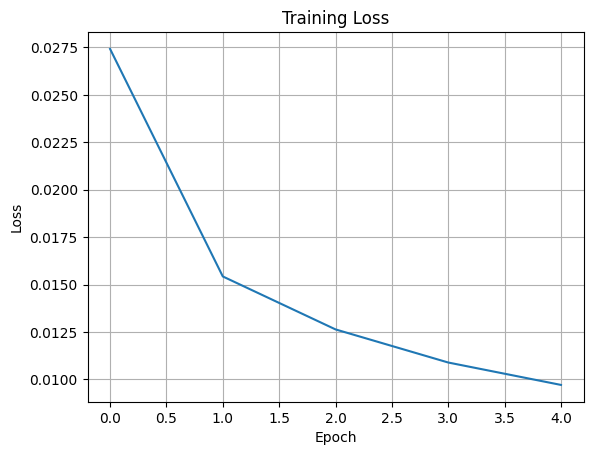

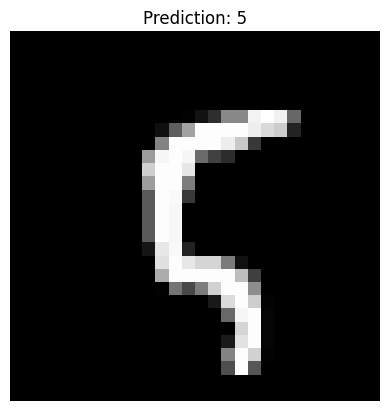

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(X_train, y_train), (_, _) = mnist.load_data()

X_train = X_train.reshape(-1, 784) / 255.0

y = np.zeros((len(y_train), 10))
y[np.arange(len(y_train)), y_train] = 1

input_size = 784
hidden_size = 64
output_size = 10

W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.01
b2 = np.zeros((1, output_size))

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def loss(y, p):
    return -np.mean(y * np.log(p + 1e-8))

epochs = 5
lr = 0.1
losses = []

for epoch in range(epochs):
    total_loss = 0

    for i in range(len(X_train)):
        x = X_train[i:i+1]
        target = y[i:i+1]

        z1 = x @ W1 + b1
        a1 = sigmoid(z1)

        z2 = a1 @ W2 + b2
        a2 = sigmoid(z2)

        total_loss += loss(target, a2)

        dz2 = a2 - target
        dW2 = a1.T @ dz2
        db2 = dz2

        dz1 = (dz2 @ W2.T) * a1 * (1 - a1)
        dW1 = x.T @ dz1
        db1 = dz1

        W2 -= lr * dW2
        b2 -= lr * db2
        W1 -= lr * dW1
        b1 -= lr * db1

    avg_loss = total_loss / len(X_train)
    losses.append(avg_loss)
    print("Epoch", epoch + 1, "Loss:", round(avg_loss, 4))

plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

def predict(img):
    img = img.reshape(1, 784) / 255.0
    a1 = sigmoid(img @ W1 + b1)
    a2 = sigmoid(a1 @ W2 + b2)
    return np.argmax(a2)

idx = 100

plt.imshow(X_train[idx].reshape(28, 28), cmap="gray")
plt.title("Prediction: " + str(predict(X_train[idx])))
plt.axis("off")
plt.show()